# EXP-5: Fine-tune ConvNeXt-Tiny — Mạnh hơn (Freeze sớm + LR cao + Warm Restarts)

Notebook này thực hiện **EXP-5** trong pipeline fine-tuning ConvNeXt-Tiny — **lệch khỏi kế hoạch gốc** (vốn dự định EXP-5 = "Augmentation nhẹ") vì sau 4 thực nghiệm liên tiếp (BASELINE → EXP-1 → EXP-2 → EXP-3 → EXP-4), **accuracy vẫn kẹt ở 85-87%** dù đã thử LR thấp, discriminative LR, cosine scheduler, và regularization (label smoothing + dropout + weight decay).

```
BASELINE → EXP-1 → EXP-2 → EXP-3 → EXP-4 → EXP-5 (Fine-tune MẠNH HƠN) → ...
```

**Chẩn đoán:** Cả 4 thực nghiệm trước đều dùng LR rất thấp (1e-6 → 3e-5) trên một checkpoint đã gần hội tụ — đủ để chỉnh sửa vi mô (micro-adjustment) nhưng không đủ lực để model thoát khỏi plateau hiện tại. EXP-4 đã kiểm soát được xu hướng val_loss tăng liên tục (giờ đi ngang thay vì tăng), nhưng accuracy/F1/AUC vẫn không nhích lên — chứng tỏ vấn đề không (chỉ) là overfitting mà là **model đã hết dư địa học thêm với cách fine-tune "nhẹ tay" này**.

**5 thay đổi so với EXP-4 (đây là thay đổi lớn, không phải điều chỉnh nhỏ):**

| # | Thay đổi | Trước (EXP-2/3/4) | Sau (EXP-5) |
|---|---|---|---|
| 1 | Đóng băng backbone sớm | Không đóng băng gì (discriminative LR) | **Đóng băng hẳn** `stem+stage1+stage2` |
| 2 | LR cho phần còn học | `stage3=1e-5`, `stage4+head=3e-5` | **`stage3=1e-4`, `stage4+head=3e-4`** (gấp ~10 lần) |
| 3 | Số epoch | 10 | **20** |
| 4 | Scheduler | CosineAnnealingLR (1 chu kỳ) | **CosineAnnealingWarmRestarts** (4 chu kỳ, mỗi 5 epoch) |
| 5 | Dropout | 0.2 | **0.3** (tăng vì LR cao rủi ro overfit lớn hơn) |

Label smoothing (0.1) và weight_decay (5e-4) giữ nguyên từ EXP-4. Thêm **early stopping** (patience=5 epoch theo val_f1) để không lãng phí compute nếu vẫn plateau.

**Nguồn checkpoint:** đọc `best_tracker.json` để lấy checkpoint tốt nhất tính đến hiện tại.

In [1]:
!pip install -q torch torchvision torchaudio
!pip install -q pandas numpy matplotlib seaborn scikit-learn tqdm


In [2]:
import os
import gc
import json
import time
import copy
import random
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import (
    convnext_tiny,
    ConvNeXt_Tiny_Weights
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

ImageFile.LOAD_TRUNCATED_IMAGES = True

print("All libraries imported successfully.")
print("PyTorch:", torch.__version__)


All libraries imported successfully.
PyTorch: 2.11.0+cu128


In [3]:
# =========================
# Reproducibility
# =========================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# =========================
# Device
# =========================

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")


print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        f"GPU Memory: "
        f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB"
    )


# =========================
# CUDA optimization
# =========================

if device.type == "cuda":
    torch.backends.cudnn.benchmark = True

    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

print("CUDA optimization configured.")


Device: cuda
GPU: Tesla T4
GPU Memory: 14.56 GB
CUDA optimization configured.


In [4]:
from google.colab import drive

drive.mount("/content/drive")


Mounted at /content/drive


In [5]:
print(os.listdir("/content/drive/MyDrive")[:30])


['7eb83c0ff94e42fbb1be86c1c38cbd18.mov', 'Cát Bà', 'IMG_6950.HEIC', 'IMG_6949.HEIC', 'bai tap c32.docx', 'Colab Notebooks', 'face_frames.zip', 'FaceForensics_Experiments', '.ipynb_checkpoints']


In [6]:
# =========================
# Google Drive
# =========================

DRIVE_ROOT = "/content/drive/MyDrive"

ZIP_NAME = "face_frames.zip"

ZIP_PATH = os.path.join(
    DRIVE_ROOT,
    ZIP_NAME
)


# =========================
# Local Colab
# =========================

EXTRACT_DIR = "/content/faceforensics"


# =========================
# Experiment output (dùng chung với BASELINE / EXP-1..4)
# =========================

EXPERIMENT_DIR = os.path.join(
    DRIVE_ROOT,
    "FaceForensics_Experiments"
)

MODEL_COMPARISON_CSV = os.path.join(
    EXPERIMENT_DIR,
    "results",
    "model_comparison.csv"
)


# =========================
# Thư mục pipeline fine-tune ConvNeXt-Tiny
# (dùng chung cho EXP-1 -> EXP-6 -> FINAL)
# =========================

FINETUNE_DIR = os.path.join(
    EXPERIMENT_DIR,
    "finetune_convnext_tiny"
)

FT_CHECKPOINT_DIR = os.path.join(
    FINETUNE_DIR,
    "checkpoints"
)

FT_HISTORY_DIR = os.path.join(
    FINETUNE_DIR,
    "histories"
)

FT_RESULT_DIR = os.path.join(
    FINETUNE_DIR,
    "results"
)

BEST_TRACKER_PATH = os.path.join(
    FINETUNE_DIR,
    "best_tracker.json"
)

EXPERIMENTS_LOG_PATH = os.path.join(
    FT_RESULT_DIR,
    "experiments_log.csv"
)


for folder in [
    EXPERIMENT_DIR,
    FINETUNE_DIR,
    FT_CHECKPOINT_DIR,
    FT_HISTORY_DIR,
    FT_RESULT_DIR
]:
    os.makedirs(folder, exist_ok=True)


print("ZIP:", ZIP_PATH)
print("Extract:", EXTRACT_DIR)
print("Finetune dir:", FINETUNE_DIR)
print("Best tracker:", BEST_TRACKER_PATH)


ZIP: /content/drive/MyDrive/face_frames.zip
Extract: /content/faceforensics
Finetune dir: /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny
Best tracker: /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny/best_tracker.json


In [7]:
# =========================
# Đọc best_tracker.json
# =========================

def init_best_tracker():
    """Fallback: nếu chưa từng chạy EXP nào, khởi tạo từ BASELINE (convnext_tiny)."""

    if os.path.exists(BEST_TRACKER_PATH):
        with open(BEST_TRACKER_PATH, "r") as f:
            return json.load(f)

    if not os.path.exists(MODEL_COMPARISON_CSV):
        raise FileNotFoundError(
            f"Không tìm thấy {MODEL_COMPARISON_CSV} và cũng chưa có "
            f"best_tracker.json. Hãy chạy Comparation_3_model.ipynb "
            f"và/hoặc các EXP trước đó."
        )

    comparison_df = pd.read_csv(MODEL_COMPARISON_CSV)

    baseline_row = comparison_df[
        comparison_df["model"] == "convnext_tiny"
    ].iloc[0]

    tracker = {
        "source_exp": "BASELINE",
        "checkpoint": baseline_row["checkpoint"],
        "best_val_f1": float(baseline_row["best_val_f1"]),
        "best_val_roc_auc": float(baseline_row["best_val_roc_auc"]),
        "best_val_accuracy": None,
    }

    with open(BEST_TRACKER_PATH, "w") as f:
        json.dump(tracker, f, indent=2)

    return tracker


best_tracker = init_best_tracker()

best_tracker.setdefault("best_val_accuracy", None)

CURRENT_BEST_CHECKPOINT = best_tracker["checkpoint"]

print("Best checkpoint hiện tại được lấy từ:", best_tracker["source_exp"])
print("Checkpoint path :", CURRENT_BEST_CHECKPOINT)
print("Best val_f1     :", best_tracker["best_val_f1"])
print("Best val_roc_auc:", best_tracker["best_val_roc_auc"])
print("Best val_accuracy:", best_tracker["best_val_accuracy"])

if not os.path.exists(CURRENT_BEST_CHECKPOINT):
    raise FileNotFoundError(
        f"Không tìm thấy checkpoint: {CURRENT_BEST_CHECKPOINT}\n"
        "Hãy kiểm tra lại đường dẫn trên Google Drive."
    )


Best checkpoint hiện tại được lấy từ: exp3_cosine_scheduler
Checkpoint path : /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny/checkpoints/convnext_tiny_exp3_cosine_scheduler_best.pth
Best val_f1     : 0.9259626508015204
Best val_roc_auc: 0.7684449590601871
Best val_accuracy: 0.8720365609825764


In [8]:
if os.path.exists(ZIP_PATH):
    size_gb = os.path.getsize(ZIP_PATH) / 1024**3
    print(f"Found ZIP: {ZIP_PATH}")
    print(f"ZIP size: {size_gb:.2f} GB")
else:
    raise FileNotFoundError(
        f"Không tìm thấy {ZIP_PATH}\n"
        "Hãy kiểm tra lại tên file hoặc vị trí trên Google Drive."
    )


Found ZIP: /content/drive/MyDrive/face_frames.zip
ZIP size: 0.93 GB


In [9]:
if os.path.exists(EXTRACT_DIR):
    print("Extract directory already exists.")
    print("Skip extraction.")

else:

    os.makedirs(EXTRACT_DIR, exist_ok=True)

    print("Extracting dataset...")
    print("This may take some time...")

    start_time = time.time()

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

    elapsed = time.time() - start_time

    print(f"Extraction completed in {elapsed:.1f} seconds.")


Extracting dataset...
This may take some time...
Extraction completed in 25.2 seconds.


In [10]:
print(os.listdir(EXTRACT_DIR))


['face_frames']


In [11]:
def find_dataset_root(base_dir):

    candidates = []

    for root, dirs, files in os.walk(base_dir):

        dir_names = {d.lower() for d in dirs}

        if "train" in dir_names and "val" in dir_names and "test" in dir_names:
            candidates.append(root)

    if len(candidates) == 0:
        raise FileNotFoundError("Không tìm thấy thư mục chứa train/val/test.")

    return candidates[0]


DATA_DIR = find_dataset_root(EXTRACT_DIR)

TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR = os.path.join(DATA_DIR, "val")
TEST_DIR = os.path.join(DATA_DIR, "test")

print("DATA_DIR : ", DATA_DIR)
print("TRAIN_DIR:", TRAIN_DIR)
print("VAL_DIR  :", VAL_DIR)
print("TEST_DIR :", TEST_DIR)


DATA_DIR :  /content/faceforensics/face_frames
TRAIN_DIR: /content/faceforensics/face_frames/train
VAL_DIR  : /content/faceforensics/face_frames/val
TEST_DIR : /content/faceforensics/face_frames/test


In [12]:
print("\nTrain:")
print(os.listdir(TRAIN_DIR))

print("\nValidation:")
print(os.listdir(VAL_DIR))



Train:
['REAL', 'FAKE']

Validation:
['REAL', 'FAKE']


In [13]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def count_images(folder):

    count = 0

    for path in Path(folder).rglob("*"):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            count += 1

    return count


def count_class_images(split_dir):

    result = {}

    for class_dir in Path(split_dir).iterdir():
        if not class_dir.is_dir():
            continue
        class_name = class_dir.name.upper()
        result[class_name] = count_images(class_dir)

    return result


train_counts = count_class_images(TRAIN_DIR)
val_counts = count_class_images(VAL_DIR)

print("========== TRAIN ==========")
for cls, count in train_counts.items():
    print(f"{cls}: {count:,}")

print("\n========== VALIDATION ==========")
for cls, count in val_counts.items():
    print(f"{cls}: {count:,}")

print("\nTotal TRAIN:", f"{sum(train_counts.values()):,}")
print("Total VALIDATION:", f"{sum(val_counts.values()):,}")


========== TRAIN ==========
REAL: 7,898
FAKE: 46,448

========== VALIDATION ==========
REAL: 1,020
FAKE: 5,982

Total TRAIN: 54,346
Total VALIDATION: 7,002


In [14]:
# =========================
# Image
# =========================

IMG_SIZE = 224


# =========================
# Training
# =========================
#
# EXP-5: "Fine-tune MANH HON"
#   - Dong bang han stem+stage1+stage2 (khong con discriminative LR
#     cho cac nhom nay nua - chung bi FREEZE hoan toan).
#   - Tang LR gap ~10 lan cho stage3 va stage4+head.
#   - Train dai hon: 20 epoch thay vi 10.
#   - Scheduler: CosineAnnealingWarmRestarts (4 chu ky, moi 5 epoch)
#     thay vi 1 chu ky cosine duy nhat.
#   - Tang Dropout 0.2 -> 0.3 vi LR cao rui ro overfit lon hon.
#   - Giu nguyen: label_smoothing=0.1, weight_decay=5e-4 (tu EXP-4).
#   - Them early stopping (patience=5 epoch theo val_f1).

BATCH_SIZE = 64
EPOCHS = 20   # <-- tang tu 10

WEIGHT_DECAY = 5e-4     # giu nguyen tu EXP-4
LABEL_SMOOTHING = 0.1   # giu nguyen tu EXP-4
DROPOUT_P = 0.3          # <-- tang tu 0.2

EARLY_STOPPING_PATIENCE = 5  # <-- MOI: dung neu val_f1 khong cai thien sau 5 epoch


# ---- Dong bang / discriminative LR ----
# stem+stage1+stage2: DONG BANG HOAN TOAN (requires_grad=False)
# chi con 2 nhom hoc: stage3 va stage4+head, voi LR CAO HON NHIEU
FREEZE_STEM_TO_STAGE2 = True

LR_STAGE3        = 1e-4   # <-- tang tu 1e-5 (gap 10 lan)
LR_STAGE4_HEAD   = 3e-4   # <-- tang tu 3e-5 (gap 10 lan)

LEARNING_RATE = LR_STAGE4_HEAD  # dùng để log/so sánh chung

# ---- Cosine Annealing Warm Restarts ----
COSINE_T_0 = 5              # so epoch cho 1 chu ky dau tien
COSINE_T_MULT = 1           # giu nguyen do dai chu ky (4 chu ky x 5 epoch = 20 epoch)
COSINE_ETA_MIN_RATIO = 0.01


# =========================
# DataLoader
# =========================

NUM_WORKERS = 4
PIN_MEMORY = (device.type == "cuda")
PERSISTENT_WORKERS = (NUM_WORKERS > 0)
PREFETCH_FACTOR = 2


# =========================
# Mixed Precision
# =========================

USE_AMP = (device.type == "cuda")


# =========================
# Classes
# =========================

CLASS_TO_LABEL = {"REAL": 0, "FAKE": 1}
LABEL_TO_CLASS = {0: "REAL", 1: "FAKE"}


# =========================
# Experiment identity
# =========================

MODEL_NAME = "convnext_tiny"
EXP_NAME = "exp5_stronger_finetune"
EXP_DESCRIPTION = (
    "Fine-tune MANH HON: dong bang han stem+stage1+stage2, tang LR gap "
    "10 lan cho stage3+stage4+head, train 20 epoch voi CosineAnnealingWarmRestarts "
    "(4 chu ky), tang dropout 0.3, giu label_smoothing=0.1 + weight_decay=5e-4 "
    "tu EXP-4, them early stopping patience=5"
)


print("IMG_SIZE:", IMG_SIZE)
print("BATCH_SIZE:", BATCH_SIZE)
print("EPOCHS:", EPOCHS, "(tang tu 10)")
print("WEIGHT_DECAY:", WEIGHT_DECAY)
print("LABEL_SMOOTHING:", LABEL_SMOOTHING)
print("DROPOUT_P:", DROPOUT_P, "(tang tu 0.2)")
print("EARLY_STOPPING_PATIENCE:", EARLY_STOPPING_PATIENCE)
print("FREEZE_STEM_TO_STAGE2:", FREEZE_STEM_TO_STAGE2)
print("LR groups (chi con 2 nhom hoc):")
print("  stage3      :", LR_STAGE3, "(tang tu 1e-5)")
print("  stage4+head :", LR_STAGE4_HEAD, "(tang tu 3e-5)")
print("Cosine Warm Restarts: T_0=", COSINE_T_0, "T_mult=", COSINE_T_MULT)
print("AMP:", USE_AMP)
print("EXP_NAME:", EXP_NAME)


IMG_SIZE: 224
BATCH_SIZE: 64
EPOCHS: 20 (tang tu 10)
WEIGHT_DECAY: 0.0005
LABEL_SMOOTHING: 0.1
DROPOUT_P: 0.3 (tang tu 0.2)
EARLY_STOPPING_PATIENCE: 5
FREEZE_STEM_TO_STAGE2: True
LR groups (chi con 2 nhom hoc):
  stage3      : 0.0001 (tang tu 1e-5)
  stage4+head : 0.0003 (tang tu 3e-5)
Cosine Warm Restarts: T_0= 5 T_mult= 1
AMP: True
EXP_NAME: exp5_stronger_finetune


In [15]:
train_transform = transforms.Compose([

    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


val_transform = transforms.Compose([

    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


print("Transforms ready (unchanged from EXP-4).")


Transforms ready (unchanged from EXP-4).


In [16]:
def create_dataframe(split_dir):

    records = []
    split_path = Path(split_dir)

    for class_dir in split_path.iterdir():

        if not class_dir.is_dir():
            continue

        class_name = class_dir.name.upper()

        if class_name not in CLASS_TO_LABEL:
            print(f"Warning: ignored class {class_name}")
            continue

        label = CLASS_TO_LABEL[class_name]

        for image_path in class_dir.rglob("*"):
            if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
                records.append({
                    "image_path": str(image_path),
                    "label": label,
                    "class_name": class_name
                })

    return pd.DataFrame(records)


train_df = create_dataframe(TRAIN_DIR)
val_df = create_dataframe(VAL_DIR)

print("TRAIN:", f"{len(train_df):,}")
print("VAL:", f"{len(val_df):,}")


TRAIN: 54,346
VAL: 7,002


In [17]:
print("\nTRAIN")
print(train_df["class_name"].value_counts())

print("\nVAL")
print(val_df["class_name"].value_counts())



TRAIN
class_name
FAKE    46448
REAL     7898
Name: count, dtype: int64

VAL
class_name
FAKE    5982
REAL    1020
Name: count, dtype: int64


In [18]:
class FaceForensicsDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]
        image_path = row["image_path"]
        label = int(row["label"])

        try:
            image = Image.open(image_path).convert("RGB")
        except Exception as e:
            print(f"\nError loading:\n{image_path}")
            raise e

        if self.transform is not None:
            image = self.transform(image)

        return image, label


In [19]:
train_dataset = FaceForensicsDataset(train_df, transform=train_transform)
val_dataset = FaceForensicsDataset(val_df, transform=val_transform)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=PERSISTENT_WORKERS,
    prefetch_factor=PREFETCH_FACTOR if NUM_WORKERS > 0 else None
)


val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=PERSISTENT_WORKERS,
    prefetch_factor=PREFETCH_FACTOR if NUM_WORKERS > 0 else None
)


print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))


Train batches: 850
Val batches: 110


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [20]:
def create_model(model_name):
    """Classifier: LayerNorm2d, Flatten, Dropout(p=DROPOUT_P), Linear (giống EXP-4, dropout tăng lên 0.3)."""

    if model_name == "convnext_tiny":

        model = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)

        in_features = model.classifier[-1].in_features

        model.classifier = nn.Sequential(
            model.classifier[0],          # LayerNorm2d
            model.classifier[1],          # Flatten
            nn.Dropout(p=DROPOUT_P),      # Dropout (p=0.3 o EXP-5)
            nn.Linear(in_features, 2)     # Linear cuoi
        )

    else:
        raise ValueError(f"Unknown model: {model_name}")

    return model


def remap_legacy_classifier_keys(state_dict):
    """
    Tương thích ngược: nếu checkpoint đến từ EXP-1/2/3 (classifier không
    có Dropout: index 0,1,2 = LayerNorm2d, Flatten, Linear), remap
    "classifier.2.*" -> "classifier.3.*" để khớp với model hiện tại
    (index 0,1,2,3 = LayerNorm2d, Flatten, Dropout, Linear).
    """

    has_legacy_linear = (
        "classifier.2.weight" in state_dict
        and "classifier.3.weight" not in state_dict
    )

    if not has_legacy_linear:
        return state_dict

    new_state_dict = {}

    for key, value in state_dict.items():

        if key.startswith("classifier.2."):
            new_key = key.replace("classifier.2.", "classifier.3.")
        else:
            new_key = key

        new_state_dict[new_key] = value

    print("  (Đã remap classifier.2.* -> classifier.3.* cho checkpoint cũ không có Dropout)")

    return new_state_dict


def load_finetune_weights(model, checkpoint_path):
    """Load trọng số từ best checkpoint trước đó, tự động remap nếu cần."""

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False  # checkpoint tu train, tin tuong duoc (PyTorch 2.6+ mac dinh weights_only=True)
    )

    state_dict = checkpoint.get("model_state_dict", checkpoint)

    state_dict = remap_legacy_classifier_keys(state_dict)

    model.load_state_dict(state_dict)

    print(f"Loaded weights from: {checkpoint_path}")

    if "metrics" in checkpoint:
        print("  Source metrics:", checkpoint["metrics"])

    return model


def apply_freeze_schedule(model):
    """
    EXP-5: đóng băng HOÀN TOÀN stem+stage1+stage2 (features[0:4]).
    Chỉ stage3, stage4, classifier còn trainable.
    """

    if not FREEZE_STEM_TO_STAGE2:
        for param in model.parameters():
            param.requires_grad = True
        return model

    # Đóng băng features[0], features[1] (stem+stage1), features[2], features[3] (stage2)
    for idx in [0, 1, 2, 3]:
        for param in model.features[idx].parameters():
            param.requires_grad = False

    # Đảm bảo phần còn lại (stage3, stage4, avgpool, classifier) trainable
    for idx in [4, 5, 6, 7]:
        for param in model.features[idx].parameters():
            param.requires_grad = True

    for param in model.avgpool.parameters():
        param.requires_grad = True

    for param in model.classifier.parameters():
        param.requires_grad = True

    return model


In [21]:
model = create_model(MODEL_NAME)

model = load_finetune_weights(model, CURRENT_BEST_CHECKPOINT)

model = apply_freeze_schedule(model)

model = model.to(device)

if device.type == "cuda":
    model = model.to(memory_format=torch.channels_last)


total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(
    f"{MODEL_NAME:20s}"
    f" | Params: {total_params / 1e6:.2f}M"
    f" | Trainable: {trainable_params / 1e6:.2f}M"
    f" ({100 * trainable_params / total_params:.1f}%)"
)

print("\nTrạng thái đóng băng theo từng phần:")
for idx, block in enumerate(model.features):
    n_trainable = sum(p.numel() for p in block.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in block.parameters())
    status = "TRAINABLE" if n_trainable == n_total else ("FROZEN" if n_trainable == 0 else "MIXED")
    print(f"  features[{idx}]: {status} ({n_total/1e6:.2f}M params)")

print("\nClassifier structure:")
print(model.classifier)


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 162MB/s]


  (Đã remap classifier.2.* -> classifier.3.* cho checkpoint cũ không có Dropout)
Loaded weights from: /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny/checkpoints/convnext_tiny_exp3_cosine_scheduler_best.pth
  Source metrics: {'loss': 0.9904242667708671, 'accuracy': 0.8720365609825764, 'precision': 0.9155228758169934, 'recall': 0.9366432631227014, 'f1': 0.9259626508015204, 'roc_auc': np.float64(0.7684449590601871)}
convnext_tiny        | Params: 27.82M | Trainable: 26.59M (95.6%)

Trạng thái đóng băng theo từng phần:
  features[0]: FROZEN (0.00M params)
  features[1]: FROZEN (0.24M params)
  features[2]: FROZEN (0.07M params)
  features[3]: FROZEN (0.92M params)
  features[4]: TRAINABLE (0.30M params)
  features[5]: TRAINABLE (10.82M params)
  features[6]: TRAINABLE (1.18M params)
  features[7]: TRAINABLE (14.29M params)

Classifier structure:
Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2):

In [22]:
class_counts = train_df["label"].value_counts().sort_index()

print("Class counts:")
for label, count in class_counts.items():
    print(LABEL_TO_CLASS[label], ":", f"{count:,}")

total_samples = len(train_df)
num_classes = 2

class_weights = []
for label in range(num_classes):
    count = class_counts[label]
    weight = total_samples / (num_classes * count)
    class_weights.append(weight)

class_weights = torch.tensor(class_weights, dtype=torch.float32, device=device)

print("\nClass weights:")
for label, weight in enumerate(class_weights):
    print(LABEL_TO_CLASS[label], ":", f"{weight.item():.4f}")


Class counts:
REAL : 7,898
FAKE : 46,448

Class weights:
REAL : 3.4405
FAKE : 0.5850


In [23]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=LABEL_SMOOTHING
)

print(criterion)


CrossEntropyLoss()


In [24]:
def build_discriminative_param_groups(model):
    """
    EXP-5: chỉ còn 2 nhóm (stem+stage1+stage2 đã bị đóng băng nên không
    có trong optimizer):
        features[4:6]  (downsample + stage3)          -> LR_STAGE3
        features[6:8] + avgpool + classifier           -> LR_STAGE4_HEAD
    """

    features = model.features

    group_stage3 = list(features[4].parameters()) + list(features[5].parameters())

    group_stage4_head = (
        list(features[6].parameters())
        + list(features[7].parameters())
        + list(model.avgpool.parameters())
        + list(model.classifier.parameters())
    )

    n_grouped = sum(
        p.numel()
        for g in [group_stage3, group_stage4_head]
        for p in g
    )
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)

    assert n_grouped == n_trainable, (
        f"Param groups không khớp tổng số tham số TRAINABLE! "
        f"grouped={n_grouped:,} vs trainable={n_trainable:,}."
    )

    param_groups = [
        {"params": group_stage3,      "lr": LR_STAGE3,      "name": "stage3"},
        {"params": group_stage4_head, "lr": LR_STAGE4_HEAD, "name": "stage4+head"},
    ]

    print("Discriminative LR param groups (chỉ phần chưa bị đóng băng):")
    for g in param_groups:
        n_params = sum(p.numel() for p in g["params"])
        print(f"  {g['name']:15s} | LR={g['lr']:.1e} | Params={n_params/1e6:.2f}M")

    return param_groups


def create_optimizer(model):

    param_groups = build_discriminative_param_groups(model)

    return torch.optim.AdamW(
        param_groups,
        weight_decay=WEIGHT_DECAY
    )


In [25]:
def create_scheduler(optimizer):
    """
    EXP-5: CosineAnnealingWarmRestarts thay cho CosineAnnealingLR đơn chu kỳ.

    Với T_0=5, T_mult=1, EPOCHS=20 -> 4 chu kỳ đều nhau (mỗi 5 epoch).
    Sau mỗi chu kỳ, LR "reset" lại gần giá trị ban đầu rồi giảm dần theo
    cosine trong chu kỳ tiếp theo -> giúp thoát local minimum nhiều lần
    thay vì chỉ giảm 1 chiều như CosineAnnealingLR.
    """

    eta_mins = [
        group["lr"] * COSINE_ETA_MIN_RATIO
        for group in optimizer.param_groups
    ]

    # CosineAnnealingWarmRestarts hỗ trợ eta_min là 1 số dùng chung cho
    # mọi param group. Vì 2 nhóm của ta có LR ban đầu khác nhau nhưng
    # cùng tỉ lệ eta_min/lr, dùng eta_min nhỏ nhất (nhóm LR thấp hơn)
    # để đảm bảo nhóm còn lại không bị chặn dưới quá cao.
    scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
        optimizer,
        T_0=COSINE_T_0,
        T_mult=COSINE_T_MULT,
        eta_min=min(eta_mins)
    )

    return scheduler


In [26]:
def train_one_epoch(model, loader, criterion, optimizer, scaler):

    model.train()

    running_loss = 0.0
    all_preds = []
    all_labels = []

    progress = tqdm(loader, desc="Train", leave=False)

    for images, labels in progress:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if device.type == "cuda":
            images = images.contiguous(memory_format=torch.channels_last)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type=device.type, enabled=USE_AMP):
            outputs = model(images)
            loss = criterion(outputs, labels)

        if USE_AMP:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()

        running_loss += loss.item() * images.size(0)

        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    epoch_f1 = f1_score(all_labels, all_preds, pos_label=1, zero_division=0)

    return epoch_loss, epoch_f1


In [27]:
def validate(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if device.type == "cuda":
                images = images.contiguous(memory_format=torch.channels_last)

            with torch.amp.autocast(device_type=device.type, enabled=USE_AMP):
                outputs = model(images)
                loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            probabilities = torch.softmax(outputs, dim=1)
            preds = torch.argmax(outputs, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probabilities[:, 1].cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    accuracy = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, pos_label=1, zero_division=0)
    recall = recall_score(all_labels, all_preds, pos_label=1, zero_division=0)
    f1 = f1_score(all_labels, all_preds, pos_label=1, zero_division=0)
    auc = roc_auc_score(all_labels, all_probs)

    return {
        "loss": epoch_loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": auc
    }


In [28]:
def save_checkpoint(model, optimizer, scheduler, scaler, epoch, metrics, best_f1):

    checkpoint_path = os.path.join(
        FT_CHECKPOINT_DIR,
        f"{MODEL_NAME}_{EXP_NAME}_best.pth"
    )

    checkpoint = {

        "model_name": MODEL_NAME,
        "exp_name": EXP_NAME,
        "finetuned_from": CURRENT_BEST_CHECKPOINT,

        "epoch": epoch,

        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict() if USE_AMP else None,

        "best_f1": best_f1,
        "metrics": metrics,

        "config": {
            "img_size": IMG_SIZE,
            "batch_size": BATCH_SIZE,
            "epochs": EPOCHS,
            "weight_decay": WEIGHT_DECAY,
            "label_smoothing": LABEL_SMOOTHING,
            "dropout_p": DROPOUT_P,
            "freeze_stem_to_stage2": FREEZE_STEM_TO_STAGE2,
            "lr_stage3": LR_STAGE3,
            "lr_stage4_head": LR_STAGE4_HEAD,
            "scheduler": "CosineAnnealingWarmRestarts",
            "cosine_t_0": COSINE_T_0,
            "cosine_t_mult": COSINE_T_MULT,
            "cosine_eta_min_ratio": COSINE_ETA_MIN_RATIO,
            "seed": SEED
        }
    }

    torch.save(checkpoint, checkpoint_path)

    return checkpoint_path


In [29]:
def train_model():

    print("\n")
    print("=" * 70)
    print(f"START FINE-TUNE: {MODEL_NAME} | {EXP_NAME}")
    print(f"Description: {EXP_DESCRIPTION}")
    print(f"Starting from: {CURRENT_BEST_CHECKPOINT}")
    print("=" * 70)

    optimizer = create_optimizer(model)
    scheduler = create_scheduler(optimizer)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    history = []
    best_f1 = -1.0
    best_auc = -1.0
    best_accuracy = -1.0
    best_loss_at_best = None
    best_epoch = -1

    epochs_without_improvement = 0

    total_start = time.time()

    for epoch in range(EPOCHS):

        epoch_start = time.time()

        print(f"\nEpoch {epoch + 1}/{EPOCHS}")

        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler
        )

        val_metrics = validate(model, val_loader, criterion)

        # CosineAnnealingWarmRestarts: step theo epoch (dang float cho phep,
        # o day dung so nguyen epoch don gian)
        scheduler.step(epoch)

        current_lrs = [g["lr"] for g in optimizer.param_groups]

        epoch_time = time.time() - epoch_start

        row = {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_f1": train_f1,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_precision": val_metrics["precision"],
            "val_recall": val_metrics["recall"],
            "val_f1": val_metrics["f1"],
            "val_roc_auc": val_metrics["roc_auc"],
            "lr_stage3": current_lrs[0],
            "lr_stage4_head": current_lrs[1],
            "epoch_time_sec": epoch_time
        }

        history.append(row)

        print(f"Train Loss : {train_loss:.4f}")
        print(f"Train F1   : {train_f1:.4f}")
        print(f"Val Loss   : {val_metrics['loss']:.4f}")
        print(f"Val Acc    : {val_metrics['accuracy']:.4f}")
        print(f"Val F1     : {val_metrics['f1']:.4f}")
        print(f"Val ROC-AUC: {val_metrics['roc_auc']:.4f}")
        print(f"LRs (stage3, stage4+head): {[f'{lr:.1e}' for lr in current_lrs]}")
        print(f"Epoch time : {epoch_time:.1f}s")

        is_better = (
            val_metrics["f1"] > best_f1
            or (val_metrics["f1"] == best_f1 and val_metrics["roc_auc"] > best_auc)
        )

        if is_better:

            best_f1 = val_metrics["f1"]
            best_auc = val_metrics["roc_auc"]
            best_accuracy = val_metrics["accuracy"]
            best_loss_at_best = val_metrics["loss"]
            best_epoch = epoch + 1
            epochs_without_improvement = 0

            checkpoint_path = save_checkpoint(
                model, optimizer, scheduler, scaler, epoch + 1, val_metrics, best_f1
            )

            print(f"✓ BEST MODEL (EXP-5) SAVED")
            print(f"  F1: {best_f1:.4f}")
            print(f"  AUC: {best_auc:.4f}")
            print(f"  Accuracy: {best_accuracy:.4f}")

        else:
            epochs_without_improvement += 1
            print(f"  (Không cải thiện: {epochs_without_improvement}/{EARLY_STOPPING_PATIENCE} epoch)")

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print(
                f"\n⏹ EARLY STOPPING tại epoch {epoch + 1}: "
                f"val_f1 không cải thiện sau {EARLY_STOPPING_PATIENCE} epoch liên tiếp."
            )
            break

    total_time = time.time() - total_start

    history_df = pd.DataFrame(history)

    history_path = os.path.join(
        FT_HISTORY_DIR,
        f"{MODEL_NAME}_{EXP_NAME}_history.csv"
    )

    history_df.to_csv(history_path, index=False)

    summary = {
        "exp_name": EXP_NAME,
        "description": EXP_DESCRIPTION,
        "model": MODEL_NAME,
        "finetuned_from": CURRENT_BEST_CHECKPOINT,
        "learning_rate": LEARNING_RATE,
        "best_epoch": best_epoch,
        "best_val_f1": best_f1,
        "best_val_roc_auc": best_auc,
        "best_val_accuracy": best_accuracy,
        "best_val_loss": best_loss_at_best,
        "total_epochs_run": len(history),
        "early_stopped": len(history) < EPOCHS,
        "total_training_time_sec": total_time,
        "average_epoch_time_sec": history_df["epoch_time_sec"].mean(),
        "checkpoint": os.path.join(
            FT_CHECKPOINT_DIR, f"{MODEL_NAME}_{EXP_NAME}_best.pth"
        ),
        "history": history_path
    }

    print("\n")
    print("=" * 70)
    print(f"FINISHED: {EXP_NAME}")
    print("=" * 70)
    print(f"Epochs chạy  : {len(history)}/{EPOCHS} {'(early stopped)' if summary['early_stopped'] else ''}")
    print(f"Best Epoch   : {best_epoch}")
    print(f"Best F1      : {best_f1:.4f}")
    print(f"Best AUC     : {best_auc:.4f}")
    print(f"Best Accuracy: {best_accuracy:.4f}  (mục tiêu >= 0.95)")
    print(f"Val Loss tại best epoch: {best_loss_at_best:.4f}")
    print(f"Avg epoch    : {summary['average_epoch_time_sec']:.1f}s")
    print(f"Total time   : {total_time / 60:.2f} min")

    return summary, history_df


In [30]:
exp5_summary, exp5_history = train_model()




START FINE-TUNE: convnext_tiny | exp5_stronger_finetune
Description: Fine-tune MANH HON: dong bang han stem+stage1+stage2, tang LR gap 10 lan cho stage3+stage4+head, train 20 epoch voi CosineAnnealingWarmRestarts (4 chu ky), tang dropout 0.3, giu label_smoothing=0.1 + weight_decay=5e-4 tu EXP-4, them early stopping patience=5
Starting from: /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny/checkpoints/convnext_tiny_exp3_cosine_scheduler_best.pth
Discriminative LR param groups (chỉ phần chưa bị đóng băng):
  stage3          | LR=1.0e-04 | Params=11.11M
  stage4+head     | LR=3.0e-04 | Params=15.47M

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Train:   0%|          | 0/850 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Train Loss : 0.4705
Train F1   : 0.9491
Val Loss   : 0.8553
Val Acc    : 0.8366
Val F1     : 0.9001
Val ROC-AUC: 0.8664
LRs (stage3, stage4+head): ['1.0e-04', '3.0e-04']
Epoch time : 451.4s
✓ BEST MODEL (EXP-5) SAVED
  F1: 0.9001
  AUC: 0.8664
  Accuracy: 0.8366

Epoch 2/20


...

Train Loss : 0.4097
Train F1   : 0.9796
Val Loss   : 0.8217
Val Acc    : 0.8589
Val F1     : 0.9166
Val ROC-AUC: 0.8070
LRs (stage3, stage4+head): ['3.5e-05', '1.0e-04']
Epoch time : 406.6s
  (Không cải thiện: 3/5 epoch)

Epoch 15/20


Train:   0%|          | 0/850 [00:00<?, ?it/s]

Train Loss : 0.3979
Train F1   : 0.9863
Val Loss   : 0.8684
Val Acc    : 0.8548
Val F1     : 0.9136
Val ROC-AUC: 0.8492
LRs (stage3, stage4+head): ['1.0e-05', '3.0e-05']
Epoch time : 404.6s
  (Không cải thiện: 4/5 epoch)

Epoch 16/20


Train:   0%|          | 0/850 [00:00<?, ?it/s]

Train Loss : 0.3916
Train F1   : 0.9902
Val Loss   : 0.8599
Val Acc    : 0.8576
Val F1     : 0.9154
Val ROC-AUC: 0.8296
LRs (stage3, stage4+head): ['1.0e-04', '3.0e-04']
Epoch time : 403.9s
  (Không cải thiện: 5/5 epoch)

⏹ EARLY STOPPING tại epoch 16: val_f1 không cải thiện sau 5 epoch liên tiếp.


FINISHED: exp5_stronger_finetune
Epochs chạy  : 16/20 (early stopped)
Best Epoch   : 11
Best F1      : 0.9168
Best AUC     : 0.8399
Best Accuracy: 0.8590  (mục tiêu >= 0.95)
Val Loss tại best epoch: 0.8472
Avg epoch    : 410.7s
Total time   : 109.87 min


In [31]:
# =========================
# So sánh EXP-5 với best hiện tại, cập nhật best_tracker.json NẾU tốt hơn
# =========================

is_new_best = (
    exp5_summary["best_val_f1"] > best_tracker["best_val_f1"]
    or (
        exp5_summary["best_val_f1"] == best_tracker["best_val_f1"]
        and exp5_summary["best_val_roc_auc"] > best_tracker["best_val_roc_auc"]
    )
)

print(f"Previous best ({best_tracker['source_exp']}):")
print(f"  val_f1      = {best_tracker['best_val_f1']:.4f}")
print(f"  val_roc_auc = {best_tracker['best_val_roc_auc']:.4f}")
print(f"  val_accuracy= {best_tracker['best_val_accuracy']}")

print(f"\nEXP-5 result:")
print(f"  val_f1      = {exp5_summary['best_val_f1']:.4f}")
print(f"  val_roc_auc = {exp5_summary['best_val_roc_auc']:.4f}")
print(f"  val_accuracy= {exp5_summary['best_val_accuracy']:.4f}")
print(f"  val_loss    = {exp5_summary['best_val_loss']:.4f}")

if is_new_best:

    best_tracker = {
        "source_exp": EXP_NAME,
        "checkpoint": exp5_summary["checkpoint"],
        "best_val_f1": exp5_summary["best_val_f1"],
        "best_val_roc_auc": exp5_summary["best_val_roc_auc"],
        "best_val_accuracy": exp5_summary["best_val_accuracy"],
    }

    with open(BEST_TRACKER_PATH, "w") as f:
        json.dump(best_tracker, f, indent=2)

    print(
        f"\n✓ EXP-5 CẢI THIỆN kết quả. "
        f"best_tracker.json đã được cập nhật -> nguồn cho thực nghiệm tiếp theo sẽ là EXP-5."
    )

else:

    print(
        f"\n✗ EXP-5 KHÔNG cải thiện so với best hiện tại "
        f"({best_tracker['source_exp']}). "
        f"best_tracker.json GIỮ NGUYÊN."
    )
    print(
        "  -> Nếu fine-tune mạnh hơn (freeze sớm + LR cao + train dài) vẫn không "
        "phá được plateau, nhiều khả năng model/kiến trúc/dữ liệu hiện tại đã "
        "chạm trần hiệu năng — cân nhắc: augmentation mạnh hơn nữa, kiểm tra lại "
        "chất lượng nhãn/dữ liệu, hoặc thử kiến trúc khác."
    )

gap_to_target = 0.95 - exp5_summary["best_val_accuracy"]
print(
    f"\nKhoảng cách tới mục tiêu Accuracy >= 95%: "
    f"{gap_to_target*100:.2f} điểm % (hiện tại: {exp5_summary['best_val_accuracy']*100:.2f}%)"
)


Previous best (exp3_cosine_scheduler):
  val_f1      = 0.9260
  val_roc_auc = 0.7684
  val_accuracy= 0.8720365609825764

EXP-5 result:
  val_f1      = 0.9168
  val_roc_auc = 0.8399
  val_accuracy= 0.8590
  val_loss    = 0.8472

✗ EXP-5 KHÔNG cải thiện so với best hiện tại (exp3_cosine_scheduler). best_tracker.json GIỮ NGUYÊN.
  -> Nếu fine-tune mạnh hơn (freeze sớm + LR cao + train dài) vẫn không phá được plateau, nhiều khả năng model/kiến trúc/dữ liệu hiện tại đã chạm trần hiệu năng — cân nhắc: augmentation mạnh hơn nữa, kiểm tra lại chất lượng nhãn/dữ liệu, hoặc thử kiến trúc khác.

Khoảng cách tới mục tiêu Accuracy >= 95%: 9.10 điểm % (hiện tại: 85.90%)


In [32]:
# =========================
# Ghi log vào experiments_log.csv (tổng hợp toàn bộ pipeline EXP-1..FINAL)
# =========================

log_row = pd.DataFrame([{
    "exp_name": EXP_NAME,
    "description": EXP_DESCRIPTION,
    "model": MODEL_NAME,
    "finetuned_from": CURRENT_BEST_CHECKPOINT,
    "learning_rate": LEARNING_RATE,
    "lr_stage3": LR_STAGE3,
    "lr_stage4_head": LR_STAGE4_HEAD,
    "freeze_stem_to_stage2": FREEZE_STEM_TO_STAGE2,
    "scheduler": "CosineAnnealingWarmRestarts",
    "weight_decay": WEIGHT_DECAY,
    "label_smoothing": LABEL_SMOOTHING,
    "dropout_p": DROPOUT_P,
    "batch_size": BATCH_SIZE,
    "epochs_planned": EPOCHS,
    "epochs_run": exp5_summary["total_epochs_run"],
    "early_stopped": exp5_summary["early_stopped"],
    "best_epoch": exp5_summary["best_epoch"],
    "best_val_f1": exp5_summary["best_val_f1"],
    "best_val_roc_auc": exp5_summary["best_val_roc_auc"],
    "best_val_accuracy": exp5_summary["best_val_accuracy"],
    "best_val_loss": exp5_summary["best_val_loss"],
    "total_training_time_sec": exp5_summary["total_training_time_sec"],
    "checkpoint": exp5_summary["checkpoint"],
    "is_new_best": is_new_best
}])

if os.path.exists(EXPERIMENTS_LOG_PATH):
    existing_log = pd.read_csv(EXPERIMENTS_LOG_PATH)
    existing_log = existing_log[existing_log["exp_name"] != EXP_NAME]
    full_log = pd.concat([existing_log, log_row], ignore_index=True)
else:
    full_log = log_row

full_log.to_csv(EXPERIMENTS_LOG_PATH, index=False)

print("Saved:", EXPERIMENTS_LOG_PATH)
display(full_log)


Saved: /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny/results/experiments_log.csv


,exp_name,description,model,finetuned_from,learning_rate,weight_decay,batch_size,epochs,best_epoch,best_val_f1,...,lr_stage4_head,scheduler,best_val_accuracy,label_smoothing,dropout_p,best_val_loss,freeze_stem_to_stage2,epochs_planned,epochs_run,early_stopped
0,exp1_lr_low,"Fine-tune LR thap (1e-5), giu nguyen cac dieu ...",convnext_tiny,/content/drive/MyDrive/FaceForensics_Experimen...,0.00001,0.0001,64,10.0,8,0.921341,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,exp2_unfreeze_discriminative_lr,Unfreeze toan bo tham so (tuong minh) + discri...,convnext_tiny,/content/drive/MyDrive/FaceForensics_Experimen...,0.00003,0.0001,64,10.0,2,0.925368,...,0.00003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,exp3_cosine_scheduler,Giu nguyen discriminative LR (4 nhom) tu EXP-2...,convnext_tiny,/content/drive/MyDrive/FaceForensics_Experimen...,0.00003,0.0001,64,10.0,2,0.925963,...,0.00003,CosineAnnealingLR,0.872037,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,exp4_loss_regularization,Giu nguyen discriminative LR + cosine schedule...,convnext_tiny,/content/drive/MyDrive/FaceForensics_Experimen...,0.00003,0.0005,64,10.0,2,0.921857,...,0.00003,CosineAnnealingLR,0.866324,0.1,0.2,0.839672,NaN,NaN,NaN,NaN
4,exp5_stronger_finetune,Fine-tune MANH HON: dong bang han stem+stage1+...,convnext_tiny,/content/drive/MyDrive/FaceForensics_Experimen...,0.00030,0.0005,64,NaN,11,0.916758,...,0.00030,CosineAnnealingWarmRestarts,0.859040,0.1,0.3,0.847249,True,20.0,16.0,True


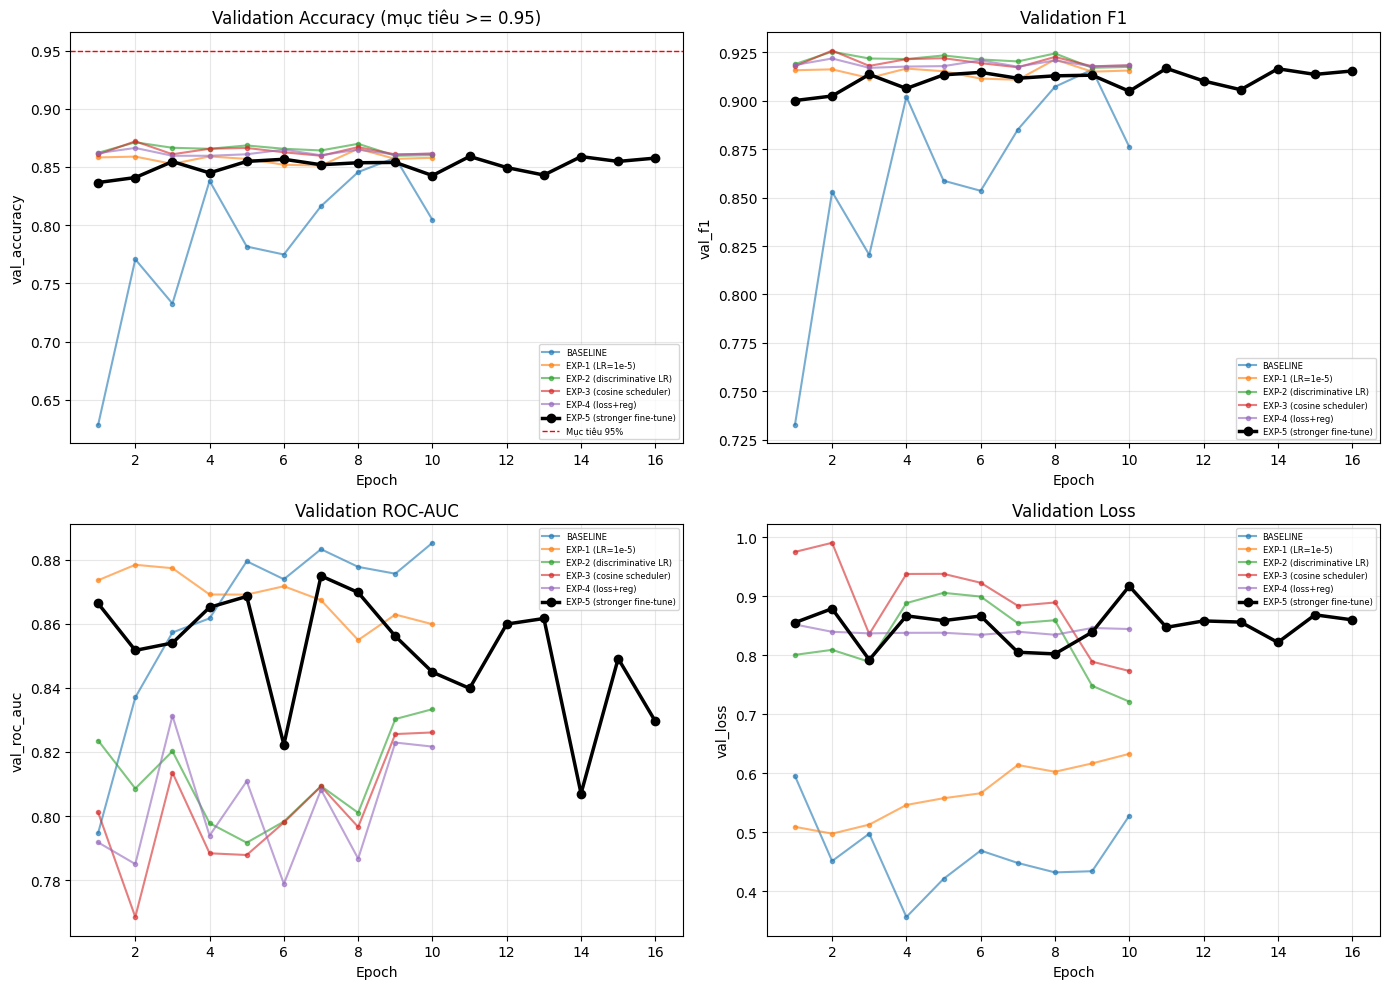

In [33]:
# =========================
# So sánh trực quan: BASELINE vs EXP-1..EXP-5
# =========================

baseline_history_path = os.path.join(
    EXPERIMENT_DIR, "histories", "convnext_tiny_history.csv"
)

exp1_history_path = os.path.join(FT_HISTORY_DIR, "convnext_tiny_exp1_lr_low_history.csv")
exp2_history_path = os.path.join(FT_HISTORY_DIR, "convnext_tiny_exp2_unfreeze_discriminative_lr_history.csv")
exp3_history_path = os.path.join(FT_HISTORY_DIR, "convnext_tiny_exp3_cosine_scheduler_history.csv")
exp4_history_path = os.path.join(FT_HISTORY_DIR, "convnext_tiny_exp4_loss_regularization_history.csv")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

metrics_to_plot = [
    ("val_accuracy", "Validation Accuracy (mục tiêu >= 0.95)"),
    ("val_f1", "Validation F1"),
    ("val_roc_auc", "Validation ROC-AUC"),
    ("val_loss", "Validation Loss"),
]

series_to_load = [
    ("BASELINE", baseline_history_path),
    ("EXP-1 (LR=1e-5)", exp1_history_path),
    ("EXP-2 (discriminative LR)", exp2_history_path),
    ("EXP-3 (cosine scheduler)", exp3_history_path),
    ("EXP-4 (loss+reg)", exp4_history_path),
]

for ax, (col, title) in zip(axes, metrics_to_plot):

    for label, path in series_to_load:
        if os.path.exists(path):
            hist = pd.read_csv(path)
            if col in hist.columns:
                ax.plot(hist["epoch"], hist[col], marker="o", markersize=3, alpha=0.6, label=label)

    ax.plot(
        exp5_history["epoch"], exp5_history[col],
        marker="o", linewidth=2.5, color="black", label="EXP-5 (stronger fine-tune)"
    )

    if col == "val_accuracy":
        ax.axhline(0.95, color="red", linestyle="--", linewidth=1, label="Mục tiêu 95%")

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(col)
    ax.legend(fontsize=6)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [34]:
print("EXP-5 hoàn tất.")
print()
print("Checkpoint của EXP-5         :", exp5_summary["checkpoint"])
print("Checkpoint TỐT NHẤT hiện tại :", best_tracker["checkpoint"])
print()
print(f"Accuracy tốt nhất hiện tại: {best_tracker['best_val_accuracy']*100:.2f}%  (mục tiêu: 95%)")
print()

if is_new_best and exp5_summary["best_val_accuracy"] > 0.87:
    print("✓ EXP-5 giúp accuracy vượt qua plateau 85-87% trước đó -> hướng đi đúng.")
    print("  Có thể tiếp tục đẩy mạnh hơn nữa (augmentation, train dài hơn) hoặc")
    print("  chuyển sang tinh chỉnh nhẹ (giảm LR) để hội tụ ổn định về đích 95%.")
elif is_new_best:
    print("△ EXP-5 cải thiện nhẹ nhưng vẫn chưa thoát hẳn plateau.")
    print("  Cân nhắc: tăng thêm số epoch/chu kỳ warm restart, hoặc kết hợp")
    print("  augmentation mạnh hơn (mixup/cutmix) ở thực nghiệm tiếp theo.")
else:
    print("✗ Fine-tune mạnh hơn (freeze sớm + LR cao + train dài) vẫn KHÔNG vượt")
    print("  qua được best hiện tại. Đây là tín hiệu quan trọng: rất có thể trần")
    print("  85-87% không đến từ cách train mà từ giới hạn của chính dữ liệu/nhãn")
    print("  hoặc kiến trúc ConvNeXt-Tiny cho bài toán này. Gợi ý bước tiếp theo:")
    print("    - Kiểm tra lại chất lượng/nhãn của tập validation (có noisy label không)")
    print("    - Thử augmentation mạnh hơn nhiều (mixup, cutmix, random erasing)")
    print("    - Cân nhắc kiến trúc lớn hơn (convnext_small/base) hoặc ensemble")


EXP-5 hoàn tất.

Checkpoint của EXP-5         : /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny/checkpoints/convnext_tiny_exp5_stronger_finetune_best.pth
Checkpoint TỐT NHẤT hiện tại : /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny/checkpoints/convnext_tiny_exp3_cosine_scheduler_best.pth

Accuracy tốt nhất hiện tại: 87.20%  (mục tiêu: 95%)

✗ Fine-tune mạnh hơn (freeze sớm + LR cao + train dài) vẫn KHÔNG vượt
  qua được best hiện tại. Đây là tín hiệu quan trọng: rất có thể trần
  85-87% không đến từ cách train mà từ giới hạn của chính dữ liệu/nhãn
  hoặc kiến trúc ConvNeXt-Tiny cho bài toán này. Gợi ý bước tiếp theo:
    - Kiểm tra lại chất lượng/nhãn của tập validation (có noisy label không)
    - Thử augmentation mạnh hơn nhiều (mixup, cutmix, random erasing)
    - Cân nhắc kiến trúc lớn hơn (convnext_small/base) hoặc ensemble
